# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

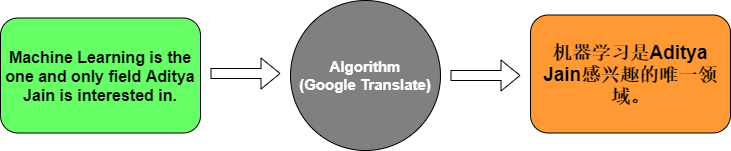

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.1429 - loss: 2.4879

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.1429 - loss: 2.4879 - val_accuracy: 0.0000e+00 - val_loss: 2.4867


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1429 - loss: 2.4782

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.1429 - loss: 2.4782 - val_accuracy: 0.0000e+00 - val_loss: 2.4889


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.8571 - loss: 0.5530 - val_accuracy: 0.0000e+00 - val_loss: 5.0349


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 716ms/step - accuracy: 0.7143 - loss: 1.7281

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 737ms/step - accuracy: 0.7143 - loss: 1.7281


Test Accuracy: 0.7142857313156128


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step


Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?



### Task 1 – Answers

1. **Embedding layer:** it turns each word index (an integer such as `5`) into a dense vector of real numbers
   (here 64 values). The vectors are learned during training, so words used in similar ways end up with similar vectors.
   It is a lookup table: row *i* of the weight matrix is the vector of word *i*.

3. **Encoder LSTM:** it reads the English sentence word by word and keeps a memory (hidden state) of what it has read.
   Its final hidden state is a fixed-size summary (context vector) of the whole input sentence.
   `RepeatVector` then copies this summary once for every word of the French output.

5. **Decoder LSTM:** it takes the sentence summary from the encoder and generates a sequence of outputs, one for each
   position of the French sentence (`return_sequences=True`), so each time step can produce one French word.

8. **Why softmax:** at every time step the model has to choose one word from the whole French vocabulary.
   Softmax turns the raw scores of the `Dense` layer into probabilities that are positive and sum to 1,
   so we can take the most likely word (`argmax`) and train the model with `sparse_categorical_crossentropy`.


### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Task 2 – Solution: English → French translation model

Steps:
1. Load the Kaggle English–French sentence pairs.
2. Keep short sentences (≤ 5 English words) and sample 40,000 pairs, so the model can be trained on a CPU.
3. Tokenize and pad both languages; add `startseq` / `endseq` tokens to the French sentences.
4. Train an **encoder–decoder LSTM with teacher forcing**. The simple `RepeatVector` model from the lab could only output
   frequent words ("je est pas…") on this large vocabulary. Here the decoder instead receives the previous French word at each
   step and starts from the encoder's final states.
5. Evaluate with BLEU score and translate e-commerce style sentences.

In [8]:
import os, glob
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
pairs = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])
pairs.columns = ["english", "french"]

print("Sentence pairs:", len(pairs))
pairs.sample(5, random_state=1)

Sentence pairs: 175621


,english,french
37931,Tom checked the date.,Tom a vérifié la date.
142019,That TV station broadcasts only movies.,Cette chaîne de télévision diffuse uniquement ...
63699,Tell me what I did wrong.,Dites-moi ce que j'ai fait de travers !
37669,They want more space.,Ils veulent plus d'espace.
165392,"If I had more money, I could move to a bigger ...","Si j'avais davantage d'argent, je pourrais dém..."


In [9]:
# Keep short sentence pairs and sample a subset to keep training time reasonable on a CPU
pairs = pairs.dropna().drop_duplicates()
en_len = pairs["english"].str.split().str.len()
fr_len = pairs["french"].str.split().str.len()
short = pairs[(en_len <= 5) & (fr_len <= 7)].sample(n=40000, random_state=42).reset_index(drop=True)
print("Pairs used for training/testing:", len(short))

Pairs used for training/testing: 40000


In [10]:
# Special tokens tell the decoder where a French sentence starts and ends
fr_marked = "startseq " + short["french"] + " endseq"

tok_en = Tokenizer()
tok_en.fit_on_texts(short["english"])
tok_fr = Tokenizer()
tok_fr.fit_on_texts(fr_marked)

en_vocab = len(tok_en.word_index) + 1
fr_vocab = len(tok_fr.word_index) + 1

X_en = pad_sequences(tok_en.texts_to_sequences(short["english"]), padding="post")
Y_fr = pad_sequences(tok_fr.texts_to_sequences(fr_marked), padding="post")
en_maxlen, fr_maxlen = X_en.shape[1], Y_fr.shape[1]

print(f"English vocab: {en_vocab}, max length: {en_maxlen}")
print(f"French vocab:  {fr_vocab}, max length: {fr_maxlen} (incl. start/end tokens)")

X_tr, X_te, Y_tr, Y_te, en_tr, en_te, fr_tr, fr_te = train_test_split(
    X_en, Y_fr, short["english"], short["french"], test_size=0.1, random_state=42)

# Teacher forcing: the decoder gets the correct previous French word as input
#   decoder input : startseq je suis content
#   decoder target: je suis content endseq
dec_in_tr, dec_out_tr = Y_tr[:, :-1], Y_tr[:, 1:]
print("Train:", X_tr.shape, " Test:", X_te.shape)

English vocab: 7148, max length: 8
French vocab:  13518, max length: 12 (incl. start/end tokens)
Train: (36000, 8)  Test: (4000, 8)


In [11]:
tf.random.set_seed(42)
latent_dim = 256

# Encoder: reads the English sentence and keeps only its final LSTM states (h, c)
enc_inputs = tf.keras.Input(shape=(None,), name="english")
enc_emb = tf.keras.layers.Embedding(en_vocab, 128, mask_zero=True)(enc_inputs)
_, state_h, state_c = tf.keras.layers.LSTM(latent_dim, return_state=True)(enc_emb)

# Decoder: starts from the encoder states and predicts the next French word at every step
dec_inputs = tf.keras.Input(shape=(None,), name="french_in")
dec_embedding = tf.keras.layers.Embedding(fr_vocab, 128, mask_zero=True)
dec_lstm = tf.keras.layers.LSTM(latent_dim, return_sequences=True, return_state=True)
dec_dense = tf.keras.layers.Dense(fr_vocab, activation="softmax")

dec_seq, _, _ = dec_lstm(dec_embedding(dec_inputs), initial_state=[state_h, state_c])
mt_model = tf.keras.Model([enc_inputs, dec_inputs], dec_dense(dec_seq))

mt_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
mt_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_in           │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 128) │    914,944 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 128) │  1,730,304 │ french_in[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 256),     │    394,240 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, None,     │    394,240 │ embedding_2[0][0… │
│                     │ 256), (None,      │            │ lstm_2[0][1],     │
│                     │ 256), (None,      │            │ lstm_2[0][2]      │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None,      │  3,474,126 │ lstm_3[0][0]      │
│                     │ 13518)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,907,854 (26.35 MB)

 Trainable params: 6,907,854 (26.35 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = mt_model.fit([X_tr, dec_in_tr], np.expand_dims(dec_out_tr, -1), epochs=20, batch_size=64,
                       validation_split=0.1, callbacks=[early_stop], verbose=2)

Epoch 1/20


507/507 - 72s - 142ms/step - accuracy: 0.3246 - loss: 4.8587 - val_accuracy: 0.3689 - val_loss: 4.2080


Epoch 2/20


507/507 - 68s - 134ms/step - accuracy: 0.4137 - loss: 3.7880 - val_accuracy: 0.4558 - val_loss: 3.5879


Epoch 3/20


507/507 - 68s - 134ms/step - accuracy: 0.4842 - loss: 3.2008 - val_accuracy: 0.5059 - val_loss: 3.2248


... (22 outputs left out)

Epoch 15/20


507/507 - 90s - 177ms/step - accuracy: 0.8250 - loss: 0.7404 - val_accuracy: 0.6315 - val_loss: 2.4523


Epoch 16/20


507/507 - 90s - 178ms/step - accuracy: 0.8440 - loss: 0.6584 - val_accuracy: 0.6339 - val_loss: 2.4644


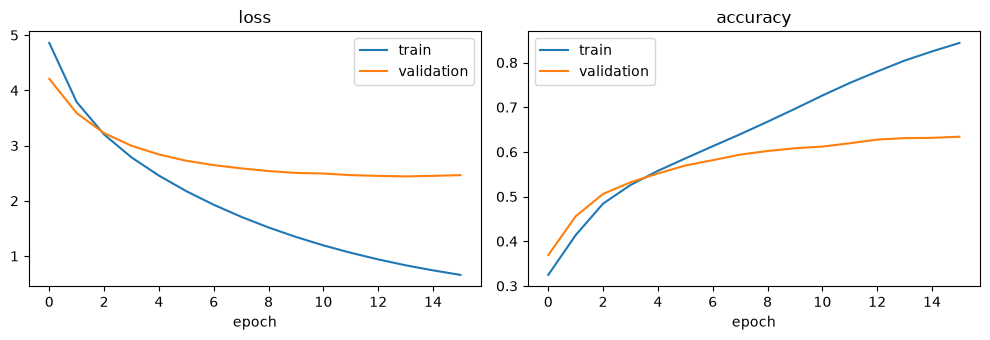

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3.5))
for i, metric in enumerate(["loss", "accuracy"]):
    plt.subplot(1, 2, i + 1)
    plt.plot(history.history[metric], label="train")
    plt.plot(history.history["val_" + metric], label="validation")
    plt.title(metric); plt.xlabel("epoch"); plt.legend()
plt.tight_layout()
plt.show()

In [14]:
# Inference models: run the encoder once, then generate French words one at a time (greedy decoding)
encoder_model = tf.keras.Model(enc_inputs, [state_h, state_c])

in_h = tf.keras.Input(shape=(latent_dim,))
in_c = tf.keras.Input(shape=(latent_dim,))
in_word = tf.keras.Input(shape=(1,))
step_out, out_h, out_c = dec_lstm(dec_embedding(in_word), initial_state=[in_h, in_c])
decoder_model = tf.keras.Model([in_word, in_h, in_c], [dec_dense(step_out), out_h, out_c])

start_id, end_id = tok_fr.word_index["startseq"], tok_fr.word_index["endseq"]

def translate_batch(sentences):
    seqs = pad_sequences(tok_en.texts_to_sequences(sentences), maxlen=en_maxlen, padding="post")
    h, c = encoder_model.predict(seqs, verbose=0)
    words = np.full((len(sentences), 1), start_id)
    outputs = [[] for _ in sentences]
    done = np.zeros(len(sentences), dtype=bool)
    for _ in range(fr_maxlen):
        probs, h, c = decoder_model.predict([words, h, c], verbose=0)
        words = probs[:, -1].argmax(-1).reshape(-1, 1)
        for i, w in enumerate(words[:, 0]):
            if w == end_id or w == 0:
                done[i] = True
            elif not done[i]:
                outputs[i].append(tok_fr.index_word[w])
        if done.all():
            break
    return [" ".join(o) for o in outputs]

def translate(sentence):
    return translate_batch([sentence])[0]

In [15]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

loss, acc = mt_model.evaluate([X_te, Y_te[:, :-1]], np.expand_dims(Y_te[:, 1:], -1), verbose=0)
print(f"Test loss: {loss:.3f}   Test word accuracy (teacher forcing, padding ignored): {acc:.3f}")

predictions = translate_batch(list(en_te))
references = [[tok_fr.sequences_to_texts([s])[0].split()] for s in tok_fr.texts_to_sequences(fr_te)]
hypotheses = [p.split() for p in predictions]
bleu = corpus_bleu(references, hypotheses, smoothing_function=SmoothingFunction().method1)
print(f"BLEU score on the {len(en_te)} test sentences: {bleu:.3f}")

Test loss: 2.371   Test word accuracy (teacher forcing, padding ignored): 0.629


BLEU score on the 4000 test sentences: 0.163


In [16]:
# Some test-set translations
for en, fr, pred in list(zip(en_te, fr_te, predictions))[:10]:
    print(f"EN:        {en}\nFR (true): {fr}\nFR (pred): {pred}\n")

EN:        How's the weather?
FR (true): Quel temps fait-il ?
FR (pred): comment y a t il de couleurs 

EN:        I missed you last night.
FR (true): Tu m'as manqué la nuit dernière.
FR (pred): j'ai manqué la nuit journée

EN:        They are about to start.
FR (true): Elles sont sur le point de commencer.
FR (pred): ils sont sur le point de commencer

EN:        You're stalling.
FR (true): Tu temporises.
FR (pred): tu es en train de grandir

EN:        I'll give you this camera.
FR (true): Je te donnerai cette caméra.
FR (pred): je te donnerai ce soir

EN:        I ran home.
FR (true): J'ai couru à la maison.
FR (pred): je me suis au commissariat

EN:        What is a think tank?
FR (true): Qu'est un cercle de réflexion ?
FR (pred): quel est l'âge de l'univers

EN:        I must be dreaming.
FR (true): Je dois rêver.
FR (pred): je dois y aller

EN:        Tom prepared for the worst.
FR (true): Tom s'est préparé au pire.
FR (pred): tom a choisi le droit de tom

EN:        She waved go

In [17]:
# E-commerce style sentences
for s in ["This is too expensive.", "I like this shirt.", "Where is the shop?",
          "It is very good.", "I want to buy it.", "Thank you very much."]:
    print(f"{s:25} -> {translate(s)}")

This is too expensive.    -> c'est trop cher


I like this shirt.        -> j'aime cette chemise


Where is the shop?        -> où est le restaurant 


It is very good.          -> c'est très bon


I want to buy it.         -> je veux le réparer


Thank you very much.      -> merci beaucoup


**Discussion**

- The encoder–decoder model learns to translate short, common sentences: product-style phrases such as
  *"This is too expensive." → "c'est trop cher"*, *"I like this shirt." → "j'aime cette chemise"* and
  *"Thank you very much." → "merci beaucoup"* come out correct. The first attempt with the lab's `RepeatVector` model
  only output frequent words ("je est pas…", BLEU = 0). Teacher forcing plus passing the encoder states to the decoder made the difference.
- Its limits show in the test set: the BLEU score is moderate, and some sentences keep the structure but use the wrong words
  (*"I must be dreaming." → "je dois y aller"*). The model was trained on only 40,000 short sentences, on a CPU.
  Words it never saw are dropped, and one fixed-size context vector has to hold the whole sentence.
- The validation loss stops improving after about 14 epochs while the training accuracy keeps rising, so the model starts
  to **overfit**. Early stopping keeps the best weights.
- For a real e-commerce product (long reviews and listings), the company should add **attention** (Lab 11) or use a
  pre-trained **Transformer** translation model, e.g. MarianMT `Helsinki-NLP/opus-mt-en-fr` or T5 (Lab 7),
  trained on far more data on GPUs.